
# Olist Customers Dataset – Data Exploration & Cleaning

## 1. Dataset Overview

**Dataset:** olist_customers_dataset.csv

**Objective:**
Understand customer information, geographical distribution,
data quality, and customer-level identifiers.

**Key Analysis Areas:**
- Customer identification
- Customer uniqueness
- Geographic distribution
- City-wise customer analysis
- State-wise customer analysis
- Data quality assessment

**Business Relevance:**
This dataset will help us understand customer distribution
and support customer segmentation and retention analysis.


# Step 1 : Initial Data Inspection

## Import Libraries 

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

### We're loading ZIP codes as strings because leading zeros are important. For example, 09790 should not become 9790.

In [3]:
df = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv",
    dtype={
        "customer_id": "string",
        "customer_unique_id": "string",
        "customer_zip_code_prefix": "string"
    }
)

In [4]:
print(f"Dataset Shape : {df.shape}")

Dataset Shape : (99441, 5)


In [5]:
display(df.head())

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
print(f"Column Names = {df.columns.tolist()}")

Column Names = ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


In [8]:
print("Data Types = ")
print(df.dtypes)

Data Types = 
customer_id                 string[python]
customer_unique_id          string[python]
customer_zip_code_prefix    string[python]
customer_city                       object
customer_state                      object
dtype: object


In [10]:
print("Dataset Information = ")
df.info()

Dataset Information = 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  string
 1   customer_unique_id        99441 non-null  string
 2   customer_zip_code_prefix  99441 non-null  string
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: object(2), string(3)
memory usage: 3.8+ MB


# Step 2 : Customer Dataset – EDA

### 2.1 Customer Record Analysis 
- How many customer records exist?

In [11]:
print(f"Total Customers Records : {len(df)}")

Total Customers Records : 99441


- How many unique customers exist?

In [14]:
print(f"Unique Customer IDs : {df["customer_id"].nunique()}")
print(f"Unique Actual Customers : {df["customer_unique_id"].nunique()}")

Unique Customer IDs : 99441
Unique Actual Customers : 96096


- Are there duplicate customer IDs?

In [16]:
print(f"Duplicate Customers IDs : {df["customer_id"].duplicated().sum()}")
print(f"Duplicate Customers Unique IDs : {df["customer_unique_id"].duplicated().sum()}")
print(f"Complete Duplicate Rows : {df.duplicated().sum()}")

Duplicate Customers IDs : 0
Duplicate Customers Unique IDs : 3345
Complete Duplicate Rows : 0


### 2.2 Missing Value Analysis  
- Are there missing values?

In [17]:
missing = pd.DataFrame(
    {
        "Missing Values" : df.isnull().sum(), 
        "Missing Percentage" : (df.isnull().mean() * 100).round(2)
    }
)

display(missing)

,Missing Values,Missing Percentage
customer_id,0,0.0
customer_unique_id,0,0.0
customer_zip_code_prefix,0,0.0
customer_city,0,0.0
customer_state,0,0.0


### 2.3 Geographic analysis
- How many unique cities and states exist?

In [18]:
print(f"Unique Cities : {df["customer_city"].nunique()}")
print(f"Unique States : {df["customer_state"].nunique()}")
print(f"Unique Zip Codes : {df["customer_zip_code_prefix"].nunique()}")

Unique Cities : 4119
Unique States : 27
Unique Zip Codes : 14994


- Which states have the highest number of customer records?

In [19]:
state_analysis = (
    df.groupby("customer_state")
    .size()
    .reset_index(name="customer_records")
    .sort_values("customer_records", ascending=False)
)

display(state_analysis)

,customer_state,customer_records
25,SP,41746
18,RJ,12852
10,MG,11635
22,RS,5466
17,PR,5045
23,SC,3637
4,BA,3380
6,DF,2140
7,ES,2033
8,GO,2020


- Which cities have the highest number of customer records?

In [20]:
city_analysis = (
    df.groupby(["customer_state", "customer_city"])
    .size()
    .reset_index(name="customer_records")
    .sort_values("customer_records", ascending=False) 
)

display(city_analysis.head(20))

,customer_state,customer_city,customer_records
4176,SP,sao paulo,15540
2788,RJ,rio de janeiro,6882
1062,MG,belo horizonte,2773
601,DF,brasilia,2131
2406,PR,curitiba,1521
3729,SP,campinas,1444
3208,RS,porto alegre,1379
372,BA,salvador,1245
3836,SP,guarulhos,1189
4160,SP,sao bernardo do campo,938


- Notice that we're grouping by both city and state because different states can have cities with the same name.

### 2.4 Geographic contribution analysis 
- What percentage of customer records come from each state?

In [22]:
state_analysis["percentage"] = (
    state_analysis["customer_records"] / len(df) * 100
).round(2)

display(state_analysis)

,customer_state,customer_records,percentage
25,SP,41746,41.98
18,RJ,12852,12.92
10,MG,11635,11.70
22,RS,5466,5.50
17,PR,5045,5.07
23,SC,3637,3.66
4,BA,3380,3.40
6,DF,2140,2.15
7,ES,2033,2.04
8,GO,2020,2.03


- Which states contribute the most customers?

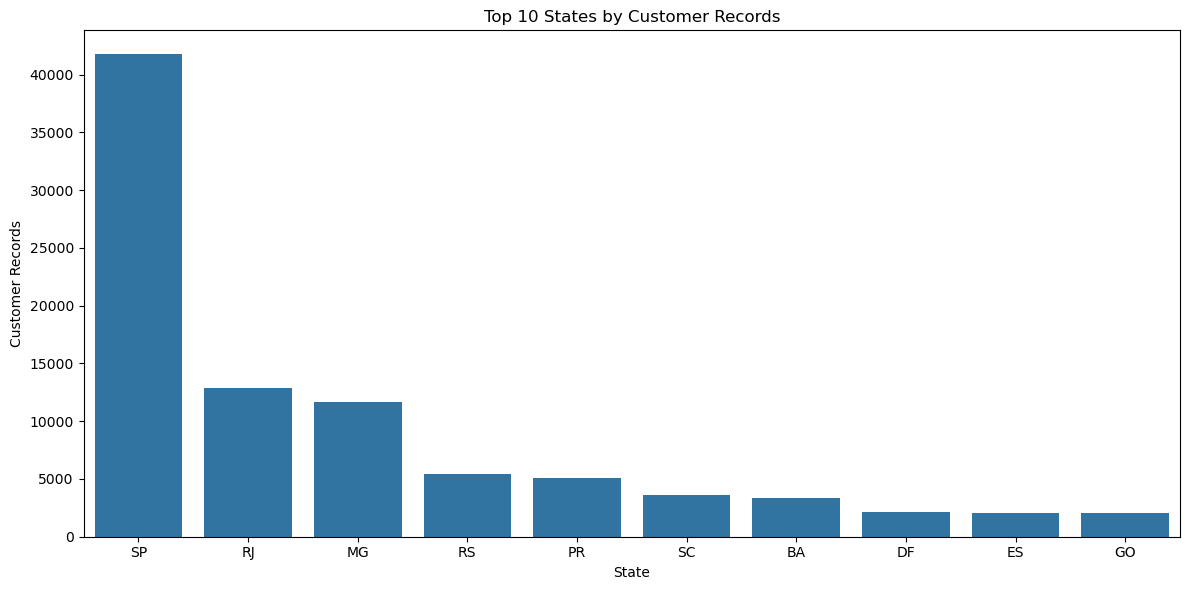

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_analysis.head(10),
    x="customer_state",
    y="customer_records"
)

plt.title("Top 10 States by Customer Records")
plt.xlabel("State")
plt.ylabel("Customer Records")
plt.tight_layout()

- How concentrated are customers geographically?
- Calculate the share contributed by the top 5 states.

In [24]:
top_5_share = state_analysis.head(5)["percentage"].sum() 
print(f"Top 5 states contribution : {round(top_5_share, 2)} %")

Top 5 states contribution : 77.17 %


### 2.5 City-level visualization
- Visualize the top 15 cities 

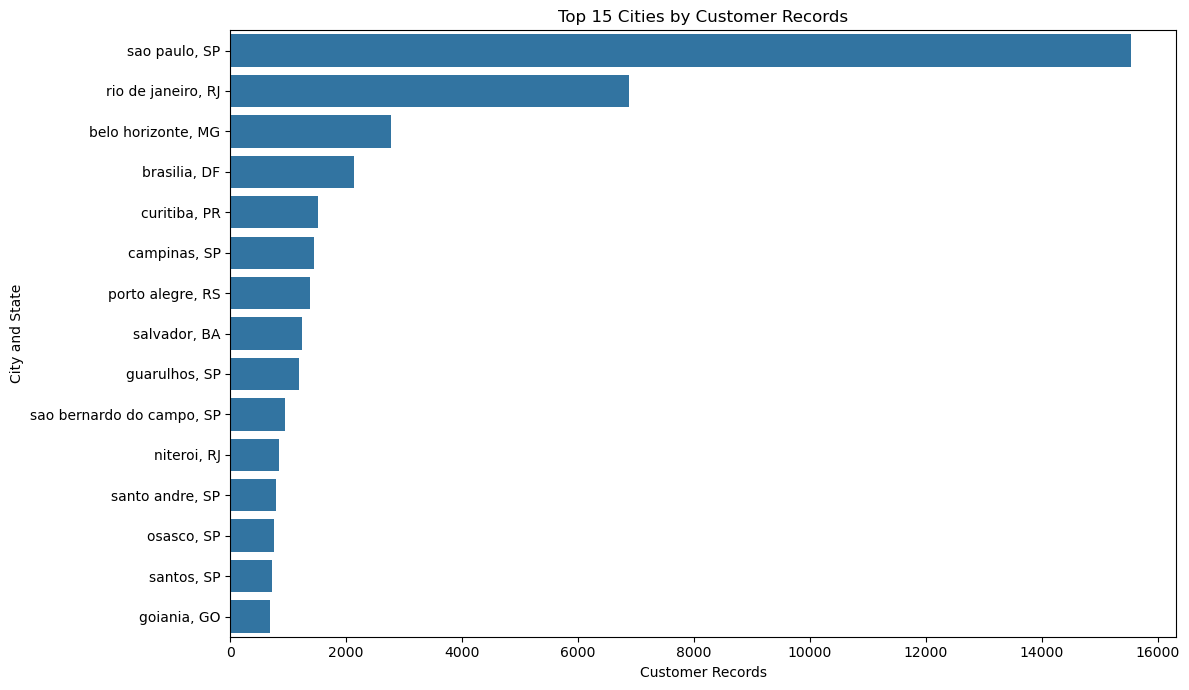

In [25]:
top_cities = city_analysis.head(15).copy()

top_cities["location"] = (
    top_cities["customer_city"] + ", " +
    top_cities["customer_state"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_cities,
    x="customer_records",
    y="location"
)

plt.title("Top 15 Cities by Customer Records")
plt.xlabel("Customer Records")
plt.ylabel("City and State")
plt.tight_layout()

- calculate unique customers by state:

In [26]:
unique_customers_state = (
    df.groupby("customer_state")["customer_unique_id"]
    .nunique() 
    .reset_index(name="unique_customers")
    .sort_values("unique_customers", ascending=False)
) 
display(unique_customers_state)

,customer_state,unique_customers
25,SP,40302
18,RJ,12384
10,MG,11259
22,RS,5277
17,PR,4882
23,SC,3534
4,BA,3277
6,DF,2075
7,ES,1964
8,GO,1952


- And cities represented by each state:

In [27]:
cities_per_state = (
    df.groupby("customer_state")["customer_city"]
    .nunique() 
    .sort_values(ascending=False)
)

display(cities_per_state)

customer_state
MG    745
SP    629
RS    379
PR    364
BA    353
SC    240
GO    178
CE    161
PE    152
RJ    149
MA    122
MT    101
ES     95
PB     92
RN     90
PA     89
PI     72
AL     68
MS     67
TO     56
SE     46
RO     35
AC      8
DF      6
AP      6
AM      5
RR      2
Name: customer_city, dtype: int64

# Additional EDA

- How many actual customers have placed multiple orders?

In [28]:
customer_frequency = (
    df.groupby("customer_unique_id")
      .size()
      .reset_index(name="customer_records")
)

repeat_customers = customer_frequency[
    customer_frequency["customer_records"] > 1
]

print("Total Actual Customers:",
      df["customer_unique_id"].nunique())

print("Repeat Customers:",
      len(repeat_customers))

print("Repeat Customer Records:",
      repeat_customers["customer_records"].sum())

print("Repeat Customer Percentage:",
      round(len(repeat_customers) /
            df["customer_unique_id"].nunique() * 100, 2), "%")

Total Actual Customers: 96096
Repeat Customers: 2997
Repeat Customer Records: 6342
Repeat Customer Percentage: 3.12 %



## 3. Initial EDA Findings

### Customer Overview
- Total records: 99,441
- Unique actual customers: 96,096
- Duplicate customer IDs: 0
- Missing values: 0
- Unique cities: 4,119
- Unique states: 27

### Geographic Insights
- SP is the leading state with 41.98% of records.
- RJ contributes 12.92%.
- MG contributes 11.70%.
- Top five states contribute 77.17%.
- MG has the highest number of represented cities (745).

### Business Insights
- Customer records are geographically concentrated.
- São Paulo city has the highest number of customer records.
- MG has wider city representation than SP.
- Repeat customer behaviour requires further investigation.

### Next Analysis
- Repeat customer frequency
- Customer distribution by purchase frequency
- State-wise repeat customer analysis
- City-wise unique customer analysis


- Which states have the highest repeat-customer counts?

In [29]:
# Identify repeat customers
repeat_ids = repeat_customers["customer_unique_id"]

# Filter their records
repeat_customer_data = df[
    df["customer_unique_id"].isin(repeat_ids)
]

# State-wise repeat customer analysis
state_repeat = (
    repeat_customer_data
    .groupby("customer_state")["customer_unique_id"]
    .nunique()
    .reset_index(name="repeat_customers")
    .sort_values("repeat_customers", ascending=False)
)

display(state_repeat)

,customer_state,repeat_customers
25,SP,1313
18,RJ,429
10,MG,348
22,RS,169
17,PR,149
23,SC,101
4,BA,95
8,GO,66
6,DF,65
7,ES,58


- Also calculate the repeat-customer percentage within each state:

In [30]:
state_total = (
    df.groupby("customer_state")["customer_unique_id"]
    .nunique()
    .reset_index(name="total_customers")
)

state_repeat_analysis = state_total.merge(
    state_repeat,
    on="customer_state",
    how="left"
)

state_repeat_analysis["repeat_customers"] = (
    state_repeat_analysis["repeat_customers"].fillna(0)
)

state_repeat_analysis["repeat_percentage"] = (
    state_repeat_analysis["repeat_customers"] /
    state_repeat_analysis["total_customers"] * 100
).round(2)

display(
    state_repeat_analysis.sort_values(
        "repeat_percentage", ascending=False
    )
)

,customer_state,total_customers,repeat_customers,repeat_percentage
0,AC,77,4,5.19
20,RO,240,11,4.58
12,MT,876,31,3.54
18,RJ,12384,429,3.46
8,GO,1952,66,3.38
25,SP,40302,1313,3.26
1,AL,401,13,3.24
24,SE,342,11,3.22
22,RS,5277,169,3.20
6,DF,2075,65,3.13


- Which cities have the highest unique customers?

In [31]:
city_unique = (
    df.groupby(["customer_state", "customer_city"])
      ["customer_unique_id"].nunique()
      .reset_index(name="unique_customers")
      .sort_values("unique_customers", ascending=False)
)

display(city_unique.head(15))

,customer_state,customer_city,unique_customers
4176,SP,sao paulo,14984
2788,RJ,rio de janeiro,6620
1062,MG,belo horizonte,2672
601,DF,brasilia,2069
2406,PR,curitiba,1465
3729,SP,campinas,1398
3208,RS,porto alegre,1326
372,BA,salvador,1209
3836,SP,guarulhos,1153
4160,SP,sao bernardo do campo,908


- Which cities have the highest repeat customers?

In [32]:
city_repeat = (
    repeat_customer_data
    .groupby(["customer_state", "customer_city"])
    ["customer_unique_id"].nunique()
    .reset_index(name="repeat_customers")
    .sort_values("repeat_customers", ascending=False)
)

display(city_repeat.head(15))

,customer_state,customer_city,repeat_customers
791,SP,sao paulo,528
450,RJ,rio de janeiro,248
154,MG,belo horizonte,97
73,DF,brasilia,64
368,PR,curitiba,48
631,SP,campinas,43
520,RS,porto alegre,42
434,RJ,niteroi,38
670,SP,guarulhos,37
50,BA,salvador,35


- What is the distribution of customer records per actual customer?

In [33]:
display(customer_frequency["customer_records"].value_counts().sort_index())

customer_records
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

- What percentage of customers have 1, 2, 3+ records?

In [34]:
customer_segments = pd.cut(
    customer_frequency["customer_records"],
    bins=[0, 1, 2, float("inf")],
    labels=["1 record", "2 records", "3+ records"]
)

segment_analysis = customer_segments.value_counts().sort_index()

display(pd.DataFrame({
    "customers": segment_analysis,
    "percentage": (segment_analysis / len(df["customer_unique_id"].unique()) * 100).round(2)
}))

,customers,percentage
customer_records,,
1 record,93099,96.88
2 records,2745,2.86
3+ records,252,0.26


- Which states have the widest ZIP-code coverage?

In [35]:
zip_state = (
    df.groupby("customer_state")["customer_zip_code_prefix"]
      .nunique()
      .sort_values(ascending=False)
)

display(zip_state)

customer_state
SP    5591
MG    1349
RJ    1199
RS     877
PR     861
BA     735
GO     540
SC     517
DF     465
PE     439
CE     384
ES     265
PA     209
MA     196
MS     186
PB     181
RN     177
MT     175
PI     154
AL     126
TO      96
SE      89
RO      75
AM      55
AC      20
AP      18
RR      15
Name: customer_zip_code_prefix, dtype: int64

- What is the customer contribution of the top 3 states?

In [36]:
print(
    "Top 3 state contribution:",
    round(state_analysis.head(3)["percentage"].sum(), 2), "%"
)

Top 3 state contribution: 66.6 %


- What percentage of customers belong to the top 10 cities?

In [37]:
top_10_city_share = (
    city_analysis.head(10)["customer_records"].sum()
    / len(df) * 100
)

print("Top 10 cities contribution:", round(top_10_city_share, 2), "%")

Top 10 cities contribution: 35.24 %


- How are customers distributed across states?

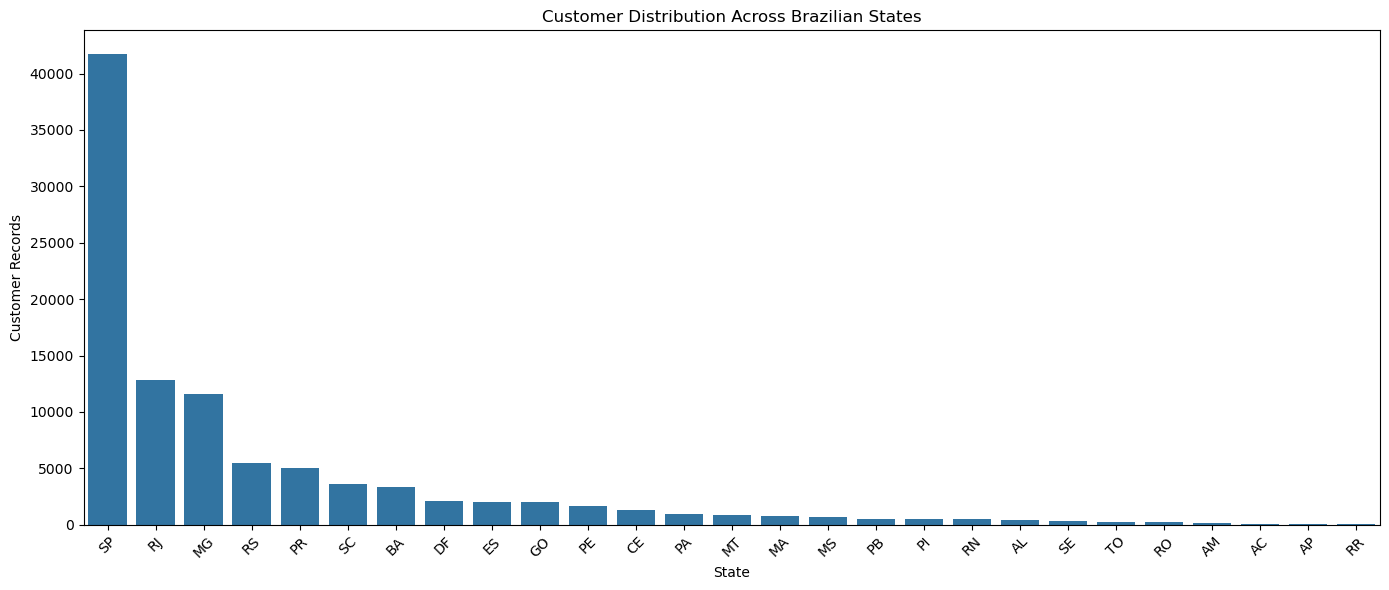

In [39]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=state_analysis,
    x="customer_state",
    y="customer_records"
)

plt.title("Customer Distribution Across Brazilian States")
plt.xlabel("State")
plt.ylabel("Customer Records")
plt.xticks(rotation=45)
plt.tight_layout()


## 3. Final EDA Findings – Customers Dataset

### Customer Overview
- Total records: 99,441
- Unique customer IDs: 99,441
- Unique actual customers: 96,096
- Duplicate customer IDs: 0
- Duplicate customer unique IDs: 3,345
- Missing values: 0

### Geographic Analysis
- Unique cities: 4,119
- Unique states: 27
- Unique ZIP codes: 14,994
- Highest customer state: SP
- Highest customer city: São Paulo

### Customer Frequency
- Single-record customers: 93,099 (96.88%)
- Two-record customers: 2,745 (2.86%)
- Three or more records: 252 (0.26%)
- Total repeat customers: 2,997 (3.12%)

### Geographic Concentration
- Top 3 states contribution: 66.60%
- Top 10 cities contribution: 35.24%
- Highest ZIP-code coverage: SP (5,591)

### Key Business Insights
1. Customer records are highly concentrated in a few states.
2. São Paulo dominates customer distribution.
3. The repeated-record customer segment is relatively small.
4. Geographic expansion and customer retention are potential
   areas for further business investigation.

### Limitation
Customer records do not independently confirm purchase frequency.
Actual repeat purchases and retention must be validated using
the Orders dataset.


# Customer Dataset – Data Cleaning

### 4.1 Customer Identifier Validation

Objective:
Validate customer identifiers to ensure they are complete,
unique where expected, and consistently formatted.

In [40]:
# Check identifier quality

for col in ["customer_id", "customer_unique_id"]:

    print(f"\n--- {col} ---")

    print("Missing values:", df[col].isna().sum())
    print("Duplicate values:", df[col].duplicated().sum())
    print("Empty strings:", df[col].eq("").sum())
    print("Whitespace issues:",
          df[col].ne(df[col].str.strip()).sum())


--- customer_id ---
Missing values: 0
Duplicate values: 0
Empty strings: 0
Whitespace issues: 0

--- customer_unique_id ---
Missing values: 0
Duplicate values: 3345
Empty strings: 0
Whitespace issues: 0


### Identifier Cleaning Results

- Both identifier columns have zero missing values.
- customer_id contains no duplicates.
- customer_unique_id has 3,345 repeated occurrences.
- No empty strings or whitespace issues were found.

**Decision:** No modifications required.
Repeated customer_unique_id values are preserved.

In [41]:
print("Data Type:", df["customer_zip_code_prefix"].dtype)

print("Missing Values:",
      df["customer_zip_code_prefix"].isnull().sum())

print("ZIP Length Distribution:")
display(df["customer_zip_code_prefix"].str.len().value_counts().sort_index())

print("Non-numeric ZIP Codes:",
      (~df["customer_zip_code_prefix"].str.fullmatch(r"\d+")).sum())

Data Type: string
Missing Values: 0
ZIP Length Distribution:


customer_zip_code_prefix
5    99441
Name: count, dtype: Int64

Non-numeric ZIP Codes: 0


### ZIP Code Validation

- ZIP codes are stored as string data type.
- All 99,441 records contain exactly 5 digits.
- No missing or non-numeric ZIP codes were found.

**Decision:** No modifications required.
Preserve ZIP codes as strings.

In [42]:
city = df["customer_city"]

print("Missing:", city.isna().sum())
print("Empty strings:", city.eq("").sum())
print("Whitespace issues:",
      city.ne(city.str.strip()).sum())

print("Uppercase city names:",
      city.ne(city.str.lower()).sum())

print("Unique city names:", city.nunique())

Missing: 0
Empty strings: 0
Whitespace issues: 0
Uppercase city names: 0
Unique city names: 4119


### City Name Validation

- No missing or empty city names.
- No leading/trailing whitespace.
- All city names are lowercase.
- 4,119 unique city names identified.

**Decision:** No modifications required.

In [43]:
state = df["customer_state"]

print("Missing:", state.isna().sum())
print("Unique states:", state.nunique())
print("State codes:", sorted(state.unique()))

print("Invalid state format:",
      (~state.str.fullmatch(r"[A-Z]{2}")).sum())

print("Whitespace issues:",
      state.ne(state.str.strip()).sum())

Missing: 0
Unique states: 27
State codes: ['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']
Invalid state format: 0
Whitespace issues: 0


### State Code Validation

- 27 unique state codes identified.
- No missing or empty values.
- All state codes contain two uppercase letters.
- No whitespace inconsistencies found.

**Decision:** No modifications required.

In [44]:
# Complete duplicate records
print("Complete duplicate rows:", df.duplicated().sum())

# City names associated with multiple states
city_state_count = (
    df.groupby("customer_city")["customer_state"]
      .nunique()
)

print("Cities associated with multiple states:",
      (city_state_count > 1).sum())

# ZIP codes associated with multiple states
zip_state_count = (
    df.groupby("customer_zip_code_prefix")["customer_state"]
      .nunique()
)

print("ZIP codes associated with multiple states:",
      (zip_state_count > 1).sum())

Complete duplicate rows: 0
Cities associated with multiple states: 163
ZIP codes associated with multiple states: 0


### Duplicate and Geographic Consistency Checks

- No complete duplicate records found.
- 163 city names are associated with multiple states.
- No ZIP-code prefixes are associated with multiple states.

**Decision:**
No records removed. City and state should be
considered together for geographic analysis.

In [45]:
print("FINAL DATA QUALITY REPORT")
print("-" * 35)

print("Original rows:", len(df))
print("Final rows:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Complete duplicates:", df.duplicated().sum())
print("Unique customer IDs:", df["customer_id"].nunique())
print("Unique actual customers:", df["customer_unique_id"].nunique())

print("\nData Types:")
print(df.dtypes)

FINAL DATA QUALITY REPORT
-----------------------------------
Original rows: 99441
Final rows: 99441
Missing values: 0
Complete duplicates: 0
Unique customer IDs: 99441
Unique actual customers: 96096

Data Types:
customer_id                 string[python]
customer_unique_id          string[python]
customer_zip_code_prefix    string[python]
customer_city                       object
customer_state                      object
dtype: object


In [48]:
df.to_csv(
    "../data/processed/olist_customers_cleaned_dataset.csv",
    index=False
)
print("Customer dataset exported successfully!")

Customer dataset exported successfully!
